## Proyecto Logistica

In [47]:
#Instalamos la libreria osmnx la cual nos permite descargar mapas y convertirlos en grafos
%pip install osmnx

In [48]:
#Instalamos folium la cual es una libreria que permite crear mapas interactivos en web con python
%pip install folium

Note: you may need to restart the kernel to use updated packages.


### 1.1 Descargar el mapa de cartagena debemos acceder a Openstreetmap y ajustar el mapa a nuestro gusto

8718 nodos
32076 aristas


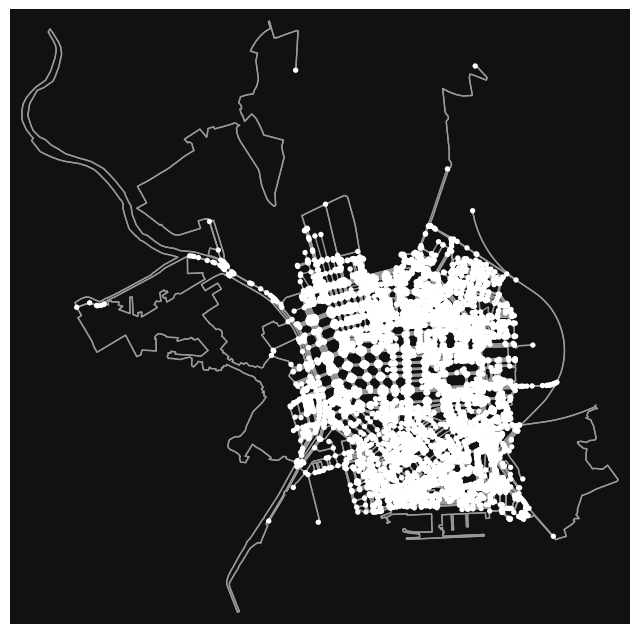

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [49]:
import osmnx as ox

# Cargar el mapa descargado
G = ox.graph_from_xml("map2.osm", simplify=True)
nodes, edges = ox.graph_to_gdfs(G)
print(len(G.nodes), "nodos") #Numero de nodos que se crean en base al mapa
print(len(G.edges), "aristas") #Numero de aristas que se crean en base al mapa
ox.plot_graph(G)

In [50]:
#Los nodos se puede ver reflejado en un dataset
nodes
# osmid -> Identificador único de cada nodo
# y -> Latitud del nodo en grados
# x -> Longitud en grados
# highway -> Etiqueta de OSM que permite saber el tipo de elemento viario del nodo
# railway -> Igual que el anterior pero para elementos ferroviarios
# geometry -> El nodo en formato geoespacial (longitud, latitud)

,y,x,highway,railway,geometry
osmid,,,,,
4760010782,37.604880,-0.987920,crossing,NaN,POINT (-0.98792 37.60488)
4760010783,37.604972,-0.988457,NaN,NaN,POINT (-0.98846 37.60497)
4760010784,37.605255,-0.989428,crossing,NaN,POINT (-0.98943 37.60526)
2329935922,37.602579,-0.980900,NaN,NaN,POINT (-0.9809 37.60258)
3474849902,37.606980,-0.977477,NaN,NaN,POINT (-0.97748 37.60698)
...,...,...,...,...,...
4983357365,37.600208,-0.988050,NaN,NaN,POINT (-0.98805 37.60021)
4983357367,37.600249,-0.987676,NaN,NaN,POINT (-0.98768 37.60025)
4983357368,37.600251,-0.987578,NaN,NaN,POINT (-0.98758 37.60025)


In [51]:
edges
# osmid -> identificador de la vía
# highway -> tipo de vía.
# name -> nombre de la calle.
# oneway -> True si solo se puede circular en un sentido. El grafo respeta el sentido de u a v.
# reversed -> True si la arista está dibujada en sentido contrario al de la vía original en OSM.
# length -> longitud del tramo en metros.
# area -> etiqueta de OSM que indica si la vía es un área (por ejemplo una plaza peatonal).
# geometry -> la forma del tramo como línea (LINESTRING), con sus coordenadas (longitud, latitud).
# maxspeed -> velocidad máxima permitida.
# bridge -> indica si el tramo es un puente.
# landuse -> uso del suelo asociado.
# lanes -> número de carriles.
# width -> anchura de la vía, si consta

osmid        highway  \
u          v           key                                           
4760010782 12059388540 0                   39894862  living_street   
                       1                 1455806762     pedestrian   
           10074925769 0                 1302028157        footway   
                       1                 1455806762     pedestrian   
           4760010783  0    [1100833441, 368144346]        footway   
...                                             ...            ...   
3817471943 3817464980  1                  378332068            NaN   
                       2                 1444006396            NaN   
           3074184014  0                  378332068            NaN   
                       1                  378332144            NaN   
                       2                 1444006397        footway   

                                           name  oneway       reversed  \
u          v           key                                               
4760010782 12059388540 0       Plaza Juan XXIII    True          False   
                       1       Plaza Juan XXIII   False           True   
           10074925769 0                    NaN   False           True   
                       1       Plaza Juan XXIII   False          False   
           4760010783  0                    NaN   False  [False, True]   
...                                         ...     ...            ...   
3817471943 3817464980  1                    NaN   False           True   
                       2    Parque de San Ginés   False          False   
           3074184014  0                    NaN   False          False   
                       1                    NaN   False          False   
                       2                    NaN   False          False   

                               length area  \
u          v           key                   
4760010782 12059388540 0     6.853697  NaN   
                       1     6.853697  yes   
           10074925769 0     3.749283  NaN   
                       1     3.749283  yes   
           4760010783  0    51.358411  NaN   
...                               ...  ...   
3817471943 3817464980  1     2.798992  NaN   
                       2     2.798992  NaN   
           3074184014  0     9.374969  NaN   
                       1     9.374969  NaN   
                       2     9.374969  NaN   

                                                                     geometry  \
u          v           key                                                      
4760010782 12059388540 0    LINESTRING (-0.98792 37.60488, -0.98787 37.60484)   
                       1    LINESTRING (-0.98792 37.60488, -0.98787 37.60484)   
           10074925769 0     LINESTRING (-0.98792 37.60488, -0.9879 37.60491)   
                       1     LINESTRING (-0.98792 37.60488, -0.9879 37.60491)   
           4760010783  0    LINESTRING (-0.98792 37.60488, -0.98797 37.604...   
...                                                                       ...   
3817471943 3817464980  1    LINESTRING (-0.97778 37.61134, -0.97778 37.61132)   
                       2    LINESTRING (-0.97778 37.61134, -0.97778 37.61132)   
           3074184014  0    LINESTRING (-0.97778 37.61134, -0.97769 37.61131)   
                       1    LINESTRING (-0.97778 37.61134, -0.97769 37.61131)   
                       2    LINESTRING (-0.97778 37.61134, -0.97769 37.61131)   

                           maxspeed bridge        landuse lanes width access  \
u          v           key                                                     
4760010782 12059388540 0        NaN    NaN            NaN   NaN   NaN    NaN   
                       1        NaN    NaN            NaN   NaN   NaN    NaN   
           10074925769 0        NaN    NaN            NaN   NaN   NaN    NaN   
                       1        NaN    NaN            NaN   NaN   NaN    NaN   
           4760010783  0        NaN    

## 1.2 Seleccionar unos 20 nodos los cuales usaremos como referencias o tiendas a las que acudir
### Para que esten balanceados en el mapa los seleccionaremos aleatoriamente

   id        nodo        lat       lon
0   1  3700818782  37.612831 -0.992213
1   2  5406984875  37.599217 -0.983496
2   3  3488749590  37.606729 -0.978344
3   4  3742505045  37.598070 -0.982266
4   5   187177926  37.606841 -0.984807


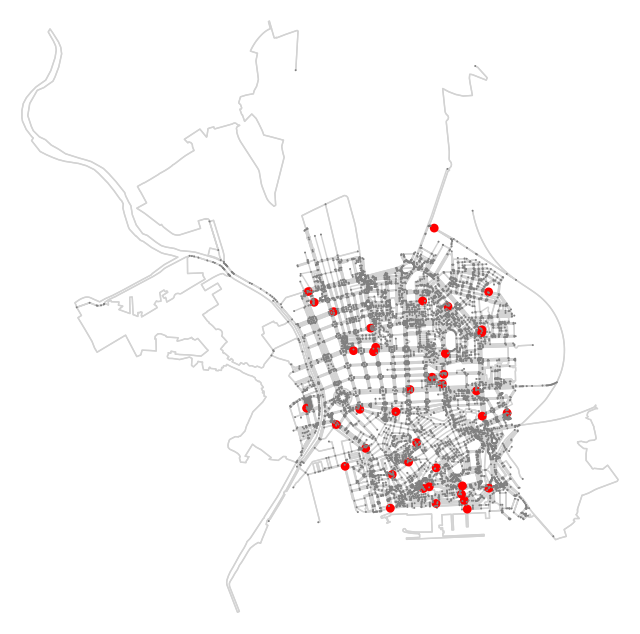

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [52]:
import random
import pandas as pd

N_NODOS = 40 # cuántos nodos usaremos como referencia
SEMILLA = 1

#Elegir N_NODOS posiciones al azar con randint
random.seed(SEMILLA)
posiciones = set() #Hacemos un conjunto para evitar duplicados
#Genreamos 20 posiciones aleatorias
while len(posiciones) < N_NODOS:
    posiciones.add(random.randint(0, len(list(G.nodes)) - 1))   # randint incluye ambos extremos   
#Guardamos los nodos de esas posiciones
mis_nodos = [list(G.nodes)[p] for p in sorted(posiciones)] #Listar los nodos seleccionados

#Recoger sus coordenadas en una tabla y guardarla
seleccion = pd.DataFrame({
    "id": range(1, N_NODOS + 1),
    "nodo": mis_nodos,                                  
    "lat": [G.nodes[n]["y"] for n in mis_nodos],       
    "lon": [G.nodes[n]["x"] for n in mis_nodos]
})
print(seleccion.head())

#Dibujar la red con los nodos elegidos en rojo
elegidos = set(mis_nodos)
color = ["red" if n in elegidos else "gray" for n in G.nodes]
size = [40 if n in elegidos else 2 for n in G.nodes]
ox.plot_graph(G, node_color=color, node_size=size,
              edge_color="lightgray", bgcolor="white")

## 1.3 Hacer mapa interactivo

In [53]:
import folium
#Creo el mapa base usando el centro aproximado de los nodos
m = folium.Map(location=[nodes["y"].mean(), nodes["x"].mean()],
                   zoom_start=14, tiles="OpenStreetMap")

#Con folium dibujo la red de calles y lo añade al mapa creado
folium.GeoJson(edges[["geometry"]],
                   style_function=lambda f: {"color": "#bbbbbb", "weight": 1}).add_to(m)

# Añado los 20 nodos seleccionados anteriormente
for _, fila in seleccion.iterrows():
        #Creo los puntos
        folium.CircleMarker([fila["lat"], fila["lon"]], radius=4, color="#444",
                            fill=True, fill_opacity=0.8,
                            tooltip=f"Parada {int(fila['id'])}").add_to(m)

m

## 1.4 Calculo matriz de distancias entre nodos

In [54]:
# Matriz de distancias
import osmnx as ox
import networkx as nx
import numpy as np
import pandas as pd

#Creo una lista con los nodos seleccionados
nodos_rojos_ids = seleccion["nodo"].tolist()
etiquetas = seleccion["id"].tolist()  


#Creo una matriz vacia, la cual rellenaremos con las distancias
n = len(nodos_rojos_ids)
matriz = np.full((n, n), np.inf)

#Calculo las distancias
for i, origen in enumerate(nodos_rojos_ids):
    #Calculo todas las distancias desde el nodo de origen a todos los demas.
    distancias = nx.single_source_dijkstra_path_length(G, origen, weight="length")
    #Obtengo la distancia desde el nodo objetivo al de origen
    for j, destino in enumerate(nodos_rojos_ids):
        matriz[i, j] = distancias.get(destino, np.inf)

#Convertir a DataFrame para verla cómoda y exportarla
df_matriz = pd.DataFrame(matriz, index=range(n), columns=range(n))
df_matriz.to_csv("matriz_distancias.csv")
print(df_matriz)

             0            1            2            3            4   \
0      0.000000  2027.310974  1765.170680  2232.352324  1210.270719   
1   2057.738407     0.000000  1205.030615   620.369551  1007.858980   
2   1766.986525  1196.210308     0.000000  1412.714006   598.765442   
3   2238.353674   561.619183  1478.851721     0.000000  1427.648287   
4   1205.752256  1070.293655   665.472786  1389.749635     0.000000   
5   1881.782858   844.196860  1623.418357   996.728303  1138.559431   
6    254.737513  2178.730761  1988.246049  2383.772111  1429.937318   
7   1406.862003  2627.947827  1730.585107  2947.403808  1639.457951   
8   2207.391276  1091.758563   472.421802  1308.141383  1039.170193   
9   1018.153608  1181.394591  1175.021744  1386.435941   592.415338   
10   473.658541  1791.284237  1322.340118  2046.174379   812.670246   
11   373.889339  2275.064890  2107.397875  2480.106240  1549.089144   
12  1300.891365  2000.863476   928.405781  2263.456505  1135.262343   
13  16